In [1]:
from torchvision import transforms
from torchvision import datasets
from torch.utils.data import Subset, DataLoader
from sklearn.model_selection import train_test_split
import torch
from torch import nn
from torchvision import models
from tqdm.auto import tqdm
from TomatoResnet34.helper_functions import accuracy_fn
import numpy as np
from collections import Counter
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

c:\Users\ROG\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomRotation(180),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.RandomAffine(degrees=0, translate=(0.1,0.1), scale=(0.9,1.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

In [3]:
import os
for root, dirs, files in os.walk("Tomato"):
    for f in files[:5]:
        print(f)

tomato__healthy (1).JPG
tomato__healthy (10).JPG
tomato__healthy (100).JPG
tomato__healthy (101).JPG
tomato__healthy (102).JPG
tomato__JAS_MIT (1).JPG
tomato__JAS_MIT (1)_aug0.JPG
tomato__JAS_MIT (1)_aug128.JPG
tomato__JAS_MIT (1)_aug160.JPG
tomato__JAS_MIT (1)_aug192.JPG
tomato__K (1).JPG
tomato__K (1)_aug0.JPG
tomato__K (1)_aug108.JPG
tomato__K (1)_aug144.JPG
tomato__K (1)_aug180.JPG
tomato__LM (1).JPG
tomato__LM (1)_aug0.JPG
tomato__LM (10).JPG
tomato__LM (10)_aug1.JPG
tomato__LM (100).JPG
tomato__MIT (1).JPG
tomato__MIT (1)_aug0.JPG
tomato__MIT (10).JPG
tomato__MIT (10)_aug1.JPG
tomato__MIT (100).JPG
tomato__N (1).JPG
tomato__N (1)_aug0.JPG
tomato__N (1)_aug141.JPG
tomato__N (1)_aug188.JPG
tomato__N (1)_aug47.JPG
tomato__N_K (1).JPG
tomato__N_K (1)_aug0.JPG
tomato__N_K (1)_aug120.JPG
tomato__N_K (1)_aug160.JPG
tomato__N_K (1)_aug40.JPG


In [4]:
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [5]:

train_full = datasets.ImageFolder(
    "Tomato",
    transform=train_transform
)

test_full = datasets.ImageFolder(
    "Tomato",
    transform=test_transform
)

In [6]:
full_dataset = datasets.ImageFolder("Tomato")  # no transform yet
# train_idx, test_idx = train_test_split(range(len(full_dataset)), test_size=0.2, random_state=42)


In [7]:
data = datasets.ImageFolder(
    "Tomato",
    transform=test_transform
)

In [8]:
labels = [label for _, label in train_full.samples]
indices = list(range(len(labels)))

In [9]:
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    
)

In [10]:
train_data = Subset(train_full, train_idx)
test_data = Subset(test_full, test_idx)

In [11]:
# train_loader = DataLoader(
#     train_data,
#     batch_size=32,
#     shuffle=True
# )

# from torch.utils.data import WeightedRandomSampler
# import numpy as np

# Get labels for the TRAIN subset only (not full dataset)


train_loader = DataLoader(
    train_data,
    batch_size=32,
    shuffle=True
)

In [12]:
test_loader = DataLoader(
    test_data,
    batch_size=32,
    shuffle=False
)

In [13]:
print("Total:", len(data))
print("Train:", len(train_loader))
print("Test:", len(test_loader))

Total: 1652
Train: 42
Test: 11


In [14]:
class_to_idx = data.class_to_idx
class_to_idx

{'tomato__JAS_MIT': 0,
 'tomato__K': 1,
 'tomato__LM': 2,
 'tomato__MIT': 3,
 'tomato__N': 4,
 'tomato__N_K': 5,
 'tomato__healthy': 6}

In [15]:
# Get class names and their numeric labels
class_to_idx = data.class_to_idx

# Reverse mapping: number -> nutrient name
idx_to_class = {v: k for k, v in class_to_idx.items()}

print("Nutrient classes:")
for idx, name in idx_to_class.items():
    print(f"{idx} -> {name}")

Nutrient classes:
0 -> tomato__JAS_MIT
1 -> tomato__K
2 -> tomato__LM
3 -> tomato__MIT
4 -> tomato__N
5 -> tomato__N_K
6 -> tomato__healthy


In [16]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [17]:
print(f"Using device: {device}")

Using device: cuda


In [18]:
from torchvision import models

model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

for param in model.parameters():
    param.requires_grad = False
# unfreeze last block + fc for fine-tuning

for param in model.layer4.parameters():
    param.requires_grad = True
model.fc = nn.Linear(model.fc.in_features, len(data.classes))
model = model.to(device)

In [19]:
model.load_state_dict(torch.load('best_Tomato_ResnetModel87.7841.pth',map_location=device))

<All keys matched successfully>

In [20]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(params = model.parameters(),
                            lr = 0.0001)

In [21]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',      # we're watching test_loss, want it to go DOWN
    factor=0.5,       # halve the LR when it plateaus
    patience=3        # wait 3 epochs of no improvement before cutting LR
)

best_acc = 0

In [22]:
EPOCHS = 10

In [23]:
results = []
image_results_train = []
image_results_test = []

In [40]:
best_acc = 87.7841

for epoch in tqdm(range(EPOCHS)):

    model.train()

    train_loss = 0

    for batch, (image, label) in enumerate(train_loader):
        image = image.to(device, dtype=torch.float32)
        label = label.to(device, dtype=torch.long)

        y_pred = model(image)
        loss = loss_fn(y_pred, label)
        train_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # ---- per-image logging, now correctly INSIDE the batch loop ----
        with torch.no_grad():
            losses = torch.nn.functional.cross_entropy(y_pred, label, reduction="none")
            predictions = y_pred.argmax(dim=1)
            for i in range(len(label)):
                actual = label[i].item()
                predicted = predictions[i].item()
                image_results_train.append({
                    "Epoch": epoch + 1,
                    "Actual_Nutrient": idx_to_class[actual],
                    "Predicted_Nutrient": idx_to_class[predicted],
                    "Loss": losses[i].item(),
                    "Accuracy": int(actual == predicted)
                })

    train_loss /= len(train_loader)

    # ---- Validation ----
    model.eval()
    test_loss = 0
    test_acc = 0

    with torch.inference_mode():
        for test_image, test_label in test_loader:
            test_image = test_image.to(device, dtype=torch.float32)
            test_label = test_label.to(device, dtype=torch.long)

            test_pred = model(test_image)
            test_loss += loss_fn(test_pred, test_label).item()
            test_acc += accuracy_fn(y_true=test_label, y_pred=test_pred.argmax(dim=1))

            test_losses = torch.nn.functional.cross_entropy(test_pred, test_label, reduction="none")
            test_predictions = test_pred.argmax(dim=1)

            for i in range(len(test_label)):
                actual = test_label[i].item()
                predicted = test_predictions[i].item()
                image_results_test.append({
                    "Epoch": epoch + 1,
                    "Actual_Nutrient": idx_to_class[actual],
                    "Predicted_Nutrient": idx_to_class[predicted],
                    "Loss": test_losses[i].item(),
                    "Accuracy": int(actual == predicted)
                })


    test_loss /= len(test_loader)
    test_acc /= len(test_loader)

    scheduler.step(test_loss)   

    if test_acc > best_acc:
        best_acc = test_acc
        torch.save(model.state_dict(), f"best_Tomato_ResnetModel{best_acc:.4f}.pth")
        print(f"Epoch {epoch+1}: New best acc {best_acc:.4f}, model saved.")
        
    # scheduler.step(test_loss)

    results.append({
        "Epoch": epoch + 1,
        "Train Loss": train_loss,
        "Test Loss": test_loss,
        "Test Accuracy": test_acc
    })

    print(f"Epoch {epoch+1}: Train loss {train_loss:.4f} | Test loss {test_loss:.4f} | Test acc {test_acc:.4f}")


 10%|█         | 1/10 [03:41<33:11, 221.26s/it]

Epoch 1: Train loss 0.1662 | Test loss 0.4495 | Test acc 84.9948


 20%|██        | 2/10 [07:27<29:55, 224.43s/it]

Epoch 2: Train loss 0.1740 | Test loss 0.4691 | Test acc 84.9948


 30%|███       | 3/10 [10:34<24:09, 207.03s/it]

...

Epoch 8: Train loss 0.1555 | Test loss 0.4466 | Test acc 84.9690


 90%|█████████ | 9/10 [28:37<03:02, 182.42s/it]

Epoch 9: Train loss 0.1719 | Test loss 0.4556 | Test acc 85.5372


 90%|█████████ | 9/10 [30:42<03:24, 204.69s/it]


KeyboardInterrupt: 

In [ ]:
model.eval()

with torch.inference_mode():
    for data in test_loader:
        image, label = data

        # Add batch dimension and move to device
        image = image.to(device)
        label = label.to(device)

        pred = model(image)

        pred_class = pred[0].argmax(dim=0).item()

        print("Actual label:", idx_to_class[label[0].item()])
        print("Predicted label:", idx_to_class[pred_class])

Actual label: tomato__K
Predicted label: tomato__K
Actual label: tomato__N_K
Predicted label: tomato__N_K
Actual label: tomato__K
Predicted label: tomato__K
Actual label: tomato__MIT
Predicted label: tomato__MIT
Actual label: tomato__K
Predicted label: tomato__K
Actual label: tomato__LM
Predicted label: tomato__LM
Actual label: tomato__N
Predicted label: tomato__N
Actual label: tomato__healthy
Predicted label: tomato__healthy
Actual label: tomato__MIT
Predicted label: tomato__healthy
Actual label: tomato__N_K
Predicted label: tomato__N_K
Actual label: tomato__N_K
Predicted label: tomato__N_K


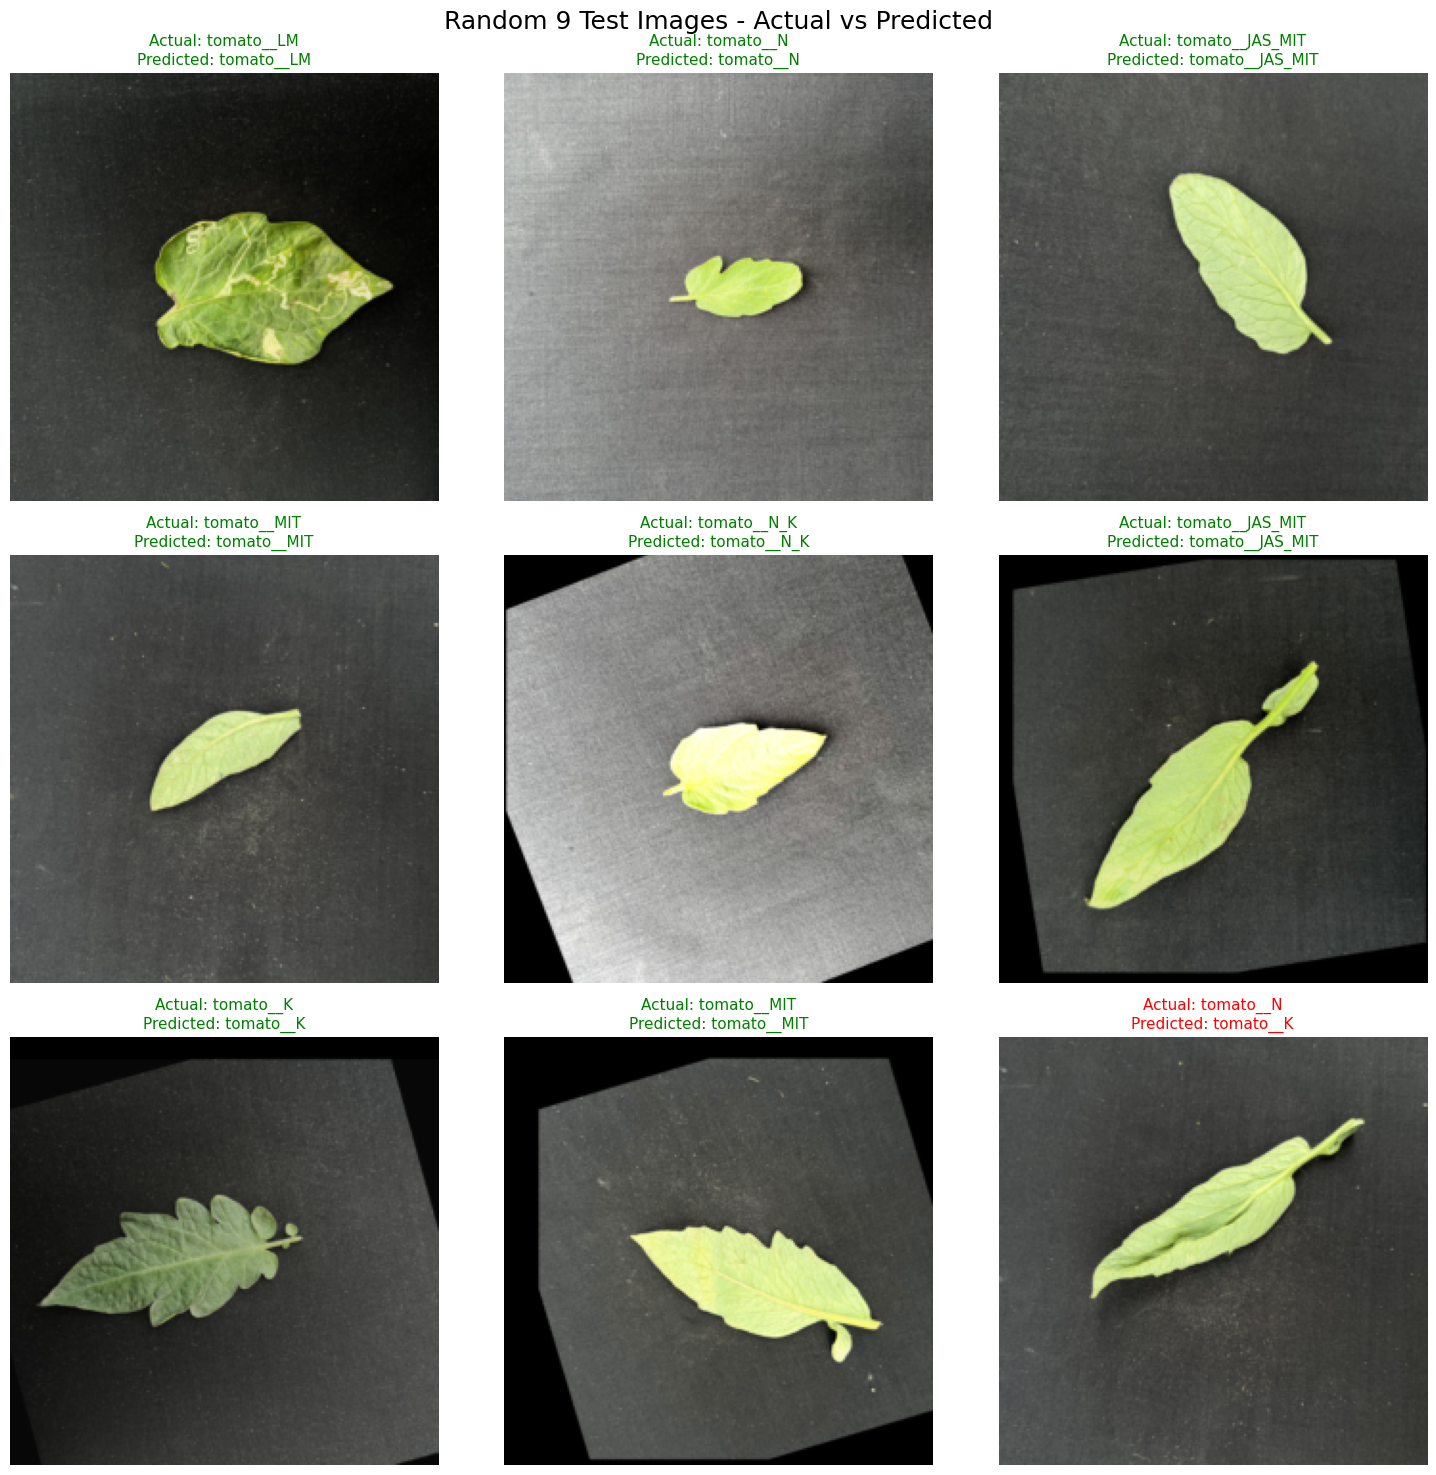

In [ ]:
import torch
import matplotlib.pyplot as plt
import random

model.eval()

# Select 9 random indices from test dataset
random_indices = random.sample(range(len(test_loader.dataset)), 9)

images = []
labels = []
predictions = []

with torch.inference_mode():

    for idx in random_indices:

        image, label = test_loader.dataset[idx]

        # Add batch dimension and move to device
        image_input = image.unsqueeze(0).to(device)

        # Prediction
        pred = model(image_input)

        pred_class = pred.argmax(dim=1).item()

        # Store
        image, label = test_loader.dataset[idx]

    # Undo normalization
        image = image.permute(1, 2, 0)
        image = image * torch.tensor([0.229, 0.224, 0.225])
        image = image + torch.tensor([0.485, 0.456, 0.406])

        image = image.clamp(0, 1)
        
        images.append(image)
        labels.append(label)
        predictions.append(pred_class)


# ---------------- PLOT ----------------

fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for i, ax in enumerate(axes.flat):

    # CHW -> HWC
    img = images[i].permute(1, 0, 2).numpy()

    ax.imshow(img)

    actual = idx_to_class[labels[i]]
    predicted = idx_to_class[predictions[i]]

    # Green = correct, Red = wrong
    if labels[i] == predictions[i]:
        color = "green"
    else:
        color = "red"

    ax.set_title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color,
        fontsize=11
    )

    ax.axis("off")

plt.suptitle(
    "Random 9 Test Images - Actual vs Predicted",
    fontsize=18
)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

df = pd.DataFrame(image_results_train)

df.to_csv("image_results_train.csv", index=False)

df = pd.DataFrame(image_results_test)

df.to_csv("image_results_test.csv", index=False)

print(df.head(20))

    Epoch  Actual_Nutrient Predicted_Nutrient      Loss  Accuracy
0       1        tomato__K          tomato__K  0.000659         1
1       1  tomato__JAS_MIT    tomato__JAS_MIT  0.000012         1
2       1       tomato__LM         tomato__LM  0.000018         1
3       1       tomato__LM         tomato__LM  0.135378         1
4       1  tomato__JAS_MIT    tomato__JAS_MIT  0.058053         1
5       1        tomato__K          tomato__K  0.003439         1
6       1      tomato__MIT        tomato__MIT  0.257566         1
7       1        tomato__K          tomato__K  0.307844         1
8       1      tomato__N_K    tomato__healthy  2.190783         0
9       1  tomato__JAS_MIT    tomato__healthy  2.477491         0
10      1        tomato__N    tomato__healthy  0.733371         0
11      1  tomato__healthy    tomato__healthy  0.000130         1
12      1        tomato__K          tomato__K  0.033835         1
13      1  tomato__healthy    tomato__healthy  0.000008         1
14      1 

In [ ]:
import pandas as pd
df = pd.DataFrame(results)

df.to_csv("data.csv", index=False)

print(df)
print("\ndata.csv saved successfully!")

    Epoch  Train Loss  Test Loss  Test Accuracy
0       1    0.257578   0.469888      83.264463
1       2    0.259094   0.427417      85.537190
2       3    0.226749   0.553150      81.301653
3       4    0.231750   0.514230      80.216942
4       5    0.238745   0.414528      86.647727
5       6    0.235910   0.600456      79.054752
6       7    0.226553   0.467056      84.400826
7       8    0.234818   0.417647      86.389463
8       9    0.225986   0.473464      84.426653
9      10    0.200478   0.467207      85.537190
10      1    0.190116   0.432405      84.142562
11      2    0.176746   0.503078      82.722107
12      3    0.194294   0.450861      84.684917
13      4    0.188289   0.422390      85.537190
14      5    0.189863   0.453327      84.969008
15      6    0.167647   0.418549      85.537190
16      7    0.172332   0.452006      84.684917
17      8    0.169610   0.445389      85.537190
18      9    0.160173   0.435841      84.710744
19     10    0.179879   0.441393      85

In [ ]:
torch.save(model.state_dict(), "nutrient_Tomato_cnnResnet.pth")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
import torch
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

model.eval()
all_preds = []
all_labels = []

with torch.inference_mode():
    for test_image, test_label in test_loader:
        test_image = test_image.to(device, dtype=torch.float32)
        test_pred = model(test_image)
        preds = test_pred.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(test_label.numpy())

class_names = [idx_to_class[i] for i in range(len(idx_to_class))]

# Per-class precision/recall/f1 -- shows you EXACTLY which classes are failing
report = classification_report(all_labels, all_preds, target_names=class_names, zero_division=0)
print(report)

with open("classification_report.txt", "w") as f:
    f.write(report)

cm = confusion_matrix(all_labels, all_preds)
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
cm_df.to_csv("confusion_matrix.csv")

confused_pairs = []
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and cm[i][j] > 0:
            confused_pairs.append((class_names[i], class_names[j], cm[i][j]))

confused_pairs.sort(key=lambda x: -x[2])
print("\nTop 20 confusion pairs (Actual -> Predicted : count):")
for actual, predicted, count in confused_pairs[:20]:
    print(f"{actual:30s} -> {predicted:30s} : {count}")


                 precision    recall  f1-score   support

tomato__JAS_MIT       0.98      0.96      0.97        46
      tomato__K       0.91      1.00      0.95        61
     tomato__LM       1.00      0.88      0.94        51
    tomato__MIT       0.83      0.62      0.71        39
      tomato__N       0.90      0.71      0.80        52
    tomato__N_K       0.95      0.86      0.90        44
tomato__healthy       0.53      0.89      0.67        38

       accuracy                           0.85       331
      macro avg       0.87      0.85      0.85       331
   weighted avg       0.88      0.85      0.86       331


Top 20 confusion pairs (Actual -> Predicted : count):
tomato__MIT                    -> tomato__healthy                : 13
tomato__N                      -> tomato__healthy                : 8
tomato__LM                     -> tomato__healthy                : 5
tomato__N                      -> tomato__K                      : 5
tomato__healthy                -> toma

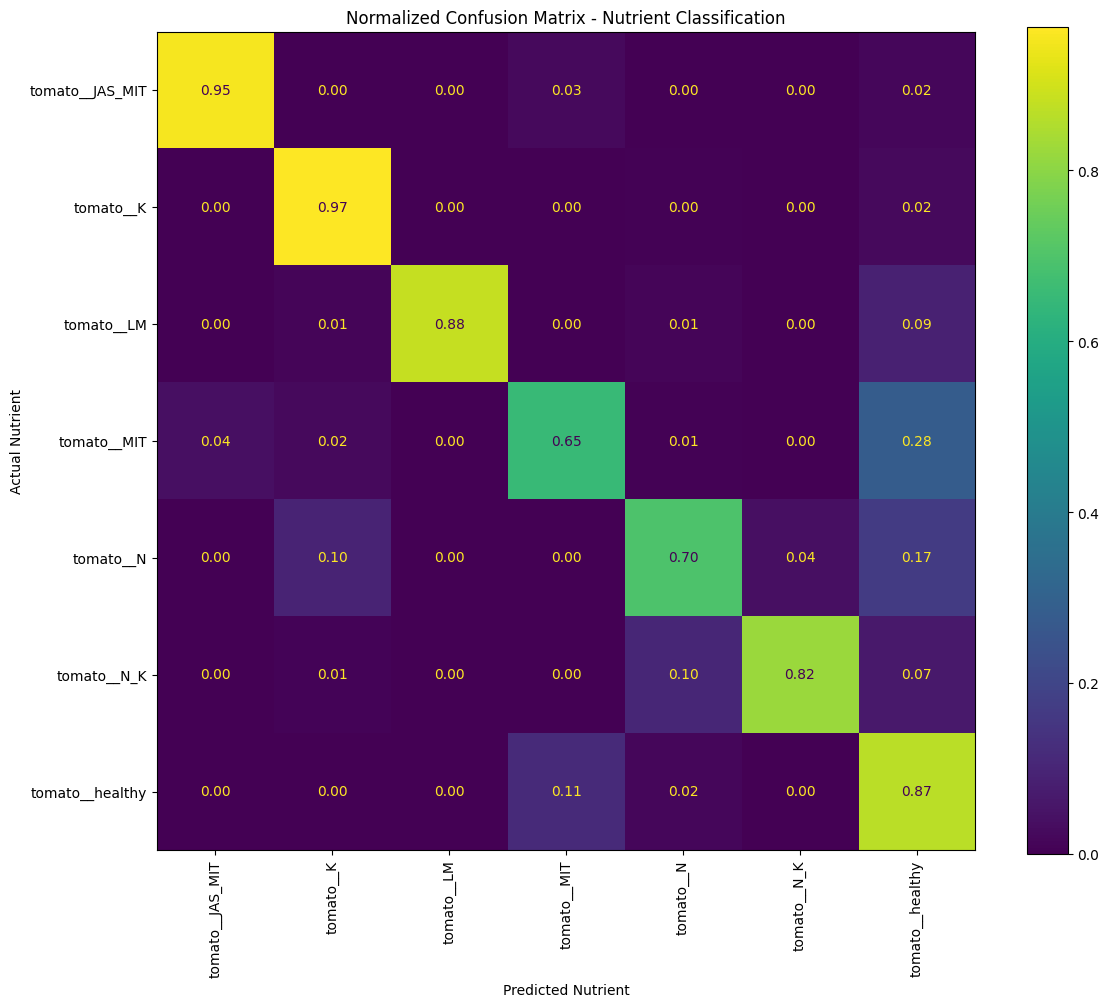

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

test_df = pd.read_csv("image_results_test.csv")

y_true = test_df["Actual_Nutrient"]
y_pred = test_df["Predicted_Nutrient"]

classes = sorted(set(y_true) | set(y_pred))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=classes,
    normalize="true"
)

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    values_format=".2f"
)

plt.title("Normalized Confusion Matrix - Nutrient Classification")
plt.xlabel("Predicted Nutrient")
plt.ylabel("Actual Nutrient")
plt.tight_layout()
plt.show()

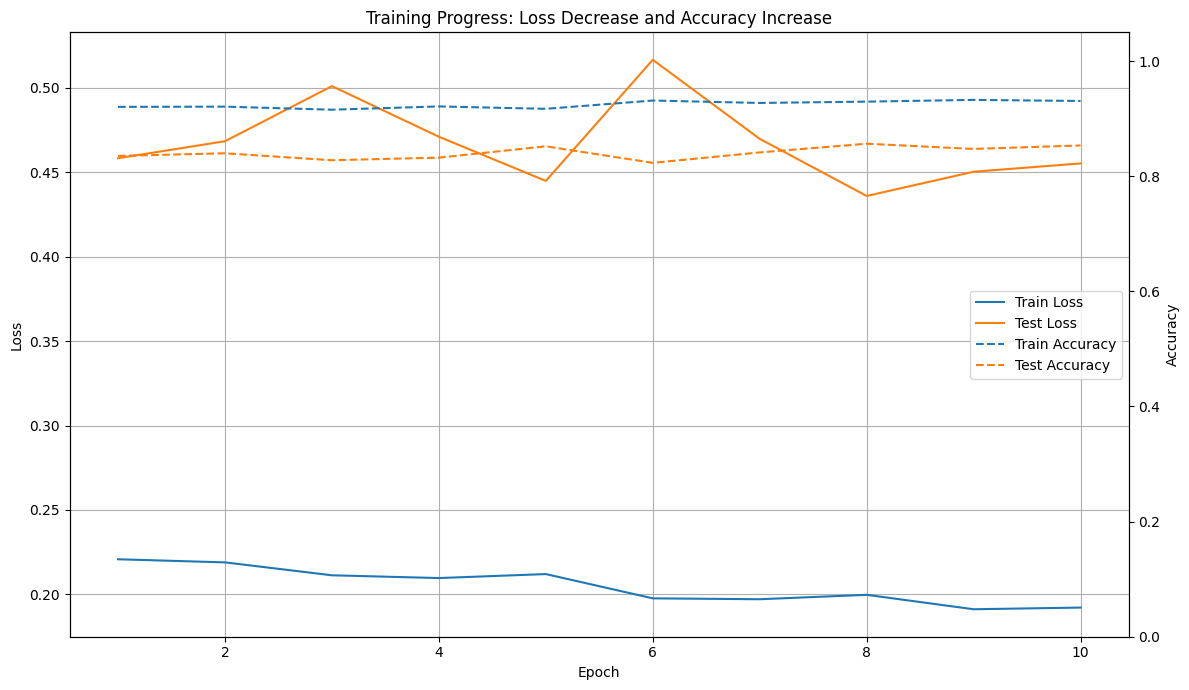

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
train_df = pd.read_csv("image_results_train.csv")
test_df = pd.read_csv("image_results_test.csv")

# Average metrics for each epoch
train_metrics = train_df.groupby("Epoch").agg({
    "Loss": "mean",
    "Accuracy": "mean"
})

test_metrics = test_df.groupby("Epoch").agg({
    "Loss": "mean",
    "Accuracy": "mean"
})

# Make sure epochs are sorted
train_metrics = train_metrics.sort_index()
test_metrics = test_metrics.sort_index()

# Create ONE plot
fig, ax1 = plt.subplots(figsize=(12, 7))


ax1.plot(
    train_metrics.index,
    train_metrics["Loss"],
    label="Train Loss"
)

ax1.plot(
    test_metrics.index,
    test_metrics["Loss"],
    label="Test Loss"
)

ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")


ax2 = ax1.twinx()

ax2.plot(
    train_metrics.index,
    train_metrics["Accuracy"],
    linestyle="--",
    label="Train Accuracy"
)

ax2.plot(
    test_metrics.index,
    test_metrics["Accuracy"],
    linestyle="--",
    label="Test Accuracy"
)

ax2.set_ylabel("Accuracy")
ax2.set_ylim(0, 1.05)


lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="center right"
)

plt.title("Training Progress: Loss Decrease and Accuracy Increase")
ax1.grid(True)
plt.tight_layout()
plt.show()